## Assignment 1
I had 3 applications for Python in this Assigment.
- Producing a diagram for the problem
- Solving a system of simultaneous equations iteratively
- Verifying my result through a simulation

### Producing a diagram for the problem
Below I use the networkx package to draw out a diagram

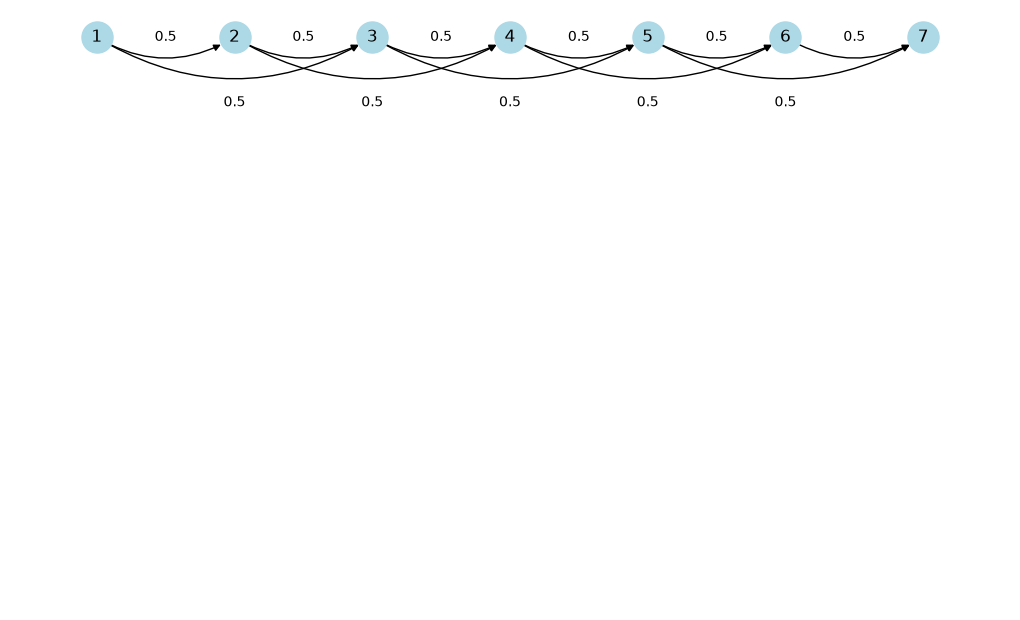

In [1]:
#Import the necessary packages
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

#Producing the adjacency matrix
n = 7 
Adj = np.zeros((n,n))

for i in range(n):
    #Give the appropriate edges appropriate weight
    if i+1 < n:
        Adj[i][i+1] = 0.5
    if i+2 < n:
        Adj[i][i+2] = 0.5

#I want my graph to be direct so have to use a digraph
G = nx.from_numpy_array(Adj, create_using = nx.DiGraph)

# Relabel nodes from (0...6) to (1...7) to match the game
mapping = {i: i+1 for i in G.nodes()}
G = nx.relabel_nodes(G, mapping)

#Defien the positions for the nodes
pos = {i: (i, 0) for i in G.nodes()}


plt.figure(figsize=(10, 6))

# Draw nodes and edges
nx.draw(
    G, pos,
    with_labels=True,
    node_size=500,
    node_color='lightblue',
    arrows = True,
    connectionstyle='arc3, rad=0.3'
)

#Now to label the edges
weights = nx.get_edge_attributes(G, 'weight')
#Edges are either short or long and will be labelled seperatel as in different positions
short_edges  = {(x,y) : weights[(x,y)] for x,y in weights if y-x == 1}
long_edges  = {(x,y) : weights[(x,y)] for x,y in weights if y-x == 2}

#Write the position for the labels
pos_short = {i: (i, 0) for i in G.nodes()}
pos_long = {i: (i, -0.06) for i in G.nodes()}

#Draw  out the edge labels
nx.draw_networkx_edge_labels(
    G, pos_short, 
    edge_labels=short_edges
)
nx.draw_networkx_edge_labels(
    G, pos_long, 
    edge_labels=long_edges
)
plt.savefig("Game Diagram.png", dpi=900)
plt.show()

### Solving a system of simultaneous equations iteratively
We use the following relation, with corresponding initial conditions, 
$$ p_{n+1} = 0.5p_n + 0.5p_{n-1}, \qquad p_0 = 1, \qquad p_1 = 0.5 $$
and iteratively calculate $p_2, p_3, p_4,$ and so on.

In the following code the approach is to initialise an array of length $m$, where $p_m$ is the probability we are trying to calculate. 

 The array will look like $ [1,0.5, 0, 0, \dots , 0 ]$ and we are trying to replace the 0s until we calculate $p_m$.

In [2]:
#what probability do we want to calculate
m = 26

def probability(m):
    #Create empty array
    prob_array = np.zeros(m)

    #Put in initial values
    prob_array[0] = 1
    prob_array[1] = 0.5

    #calculate following values
    for i in range(1, m-1):
        prob_array [i+1] = 0.5* prob_array[i] + 0.5*prob_array[i-1]

    print(f"The array of probabilities is \n {prob_array}")
    #return the probability we wanted
    return prob_array[-1]


print(f"We have calculate that the probability is {probability(m)}")



The array of probabilities is 
 [1.         0.5        0.75       0.625      0.6875     0.65625
 0.671875   0.6640625  0.66796875 0.66601562 0.66699219 0.66650391
 0.66674805 0.66662598 0.66668701 0.66665649 0.66667175 0.66666412
 0.66666794 0.66666603 0.66666698 0.66666651 0.66666675 0.66666663
 0.66666669 0.66666666]
We have calculate that the probability is 0.6666666567325592


### Verifying my result through a simulation
We want to verify our results we will run a simulation of the game. 
The following programme simulates a number of trials and calculate the average number of times that 26 is hit.
We follow by using the random package to simulate a coin flip. 

In [3]:
import random

#A function to verify if we hit 26
def hit():
    i = 1
    while i <= 25:
        #simulate coin flip
        add = random.randint(1,2)
        i += add
    #return 1 if hit, and 0 otherwise
    if i == 26:
        return 1
    else:
        return 0

#Compute the average hit rate over a number of trials
trials = 100000
total  = 0
for j in range(trials):
    total += hit()

print(f"Our simulation of the game has produced an estimated probability of {total/trials}")
    



Our simulation of the game has produced an estimated probability of 0.66774
